# Tabby’s Star: a reproducible detection case study

In [1]:
%matplotlib inline

# Import analysis and plotting tools and record the package version.
import os
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import nahiku
from nahiku import Nahiku
print(f"Nāhiku {nahiku.__version__}")

# Set plot resolution and simplify the axes borders.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/tmp/nahiku-02/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Nāhiku 0.2.0


## 1. Load the fixed observation with Lightkurve

Kepler quarter 16 contains the D1500 complex described by [Boyajian et al. (2016)](https://doi.org/10.1093/mnras/stw218). We focus on BKJD 1507–1530, retaining baseline on either side of the deep event.

The default loading path uses **Lightkurve** and MAST. A fixed CSV subset of the observations supports an offline run (`NAHIKU_OFFLINE=1`). Install the package’s `data` and `docs` extras. This example illustrates detection methods; it does not establish the physical origin of detected features.

The observation manifest records the mission, pipeline, cadence, quarter or sector, product URI, and SHA-256 checksum. We use PDCSAP flux with Lightkurve’s default quality mask, reject invalid values, and normalize by the selected window’s median. BKJD is BJD − 2454833; BTJD is BJD − 2457000. Neither is a sample index.

kplr008462852-2013098041711_llc.fits 1054 valid observations


/tmp/nahiku-02/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


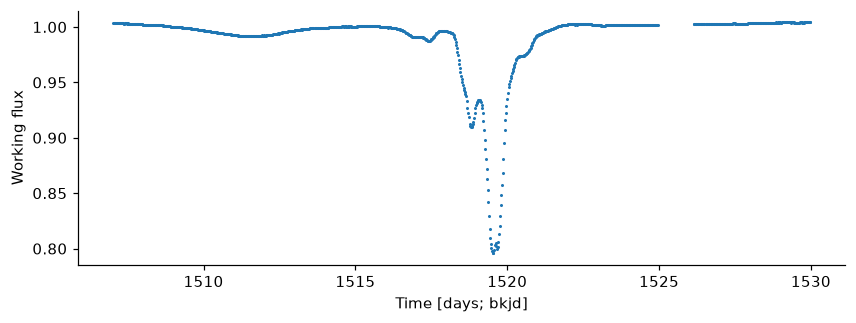

In [2]:
# Load archive tools and checksum utilities for observation provenance.
import hashlib
import lightkurve as lk
from astropy.time import Time

# Run from examples/ or the repository root. No source-path modification is needed.
data_dir = Path("data") if Path("data/tabbys_star.json").exists() else Path("examples/data")

# Read the fixed observation selection and choose the data source and cache.
manifest = json.loads((data_dir / "tabbys_star.json").read_text())
OFFLINE = os.environ.get("NAHIKU_OFFLINE", "0") == "1"
cache = Path(os.environ.get("NAHIKU_CACHE", str(Path.home() / ".cache/nahiku")))
if not OFFLINE:
    # Query the archive and require the exact product recorded in the manifest.
    products = lk.search_lightcurve(manifest["target"], **manifest["selection"])
    selected = products[products.table["dataURI"] == manifest["data_uri"]]
    if len(selected) != 1:
        raise RuntimeError("The frozen product is unavailable; inspect the archive selection")
    # Download quality-filtered observations and verify the product checksum.
    lightcurve = selected.download(download_dir=str(cache), quality_bitmask="default")
    digest = hashlib.sha256(Path(lightcurve.filename).read_bytes()).hexdigest()
    if digest != manifest["sha256"]:
        raise RuntimeError("Archive product changed; review provenance before updating the manifest")
    # Restrict the analysis to the recorded time window before conversion.
    lo, hi = manifest["window_days"]
    lightcurve = lightcurve[(lightcurve.time.value >= lo) & (lightcurve.time.value <= hi)]
    raw = Nahiku.from_lightkurve(lightcurve)
else:
    # Verify the local fixture and construct a Lightkurve object for conversion.
    fixture = data_dir / manifest["fixture"]
    assert hashlib.sha256(fixture.read_bytes()).hexdigest() == manifest["fixture_sha256"]
    values = np.genfromtxt(fixture, delimiter=",", names=True)
    lightcurve = lk.LightCurve(time=Time(values["time"], format=manifest["time_format"], scale="tdb"),
                              flux=values["flux"], flux_err=values["flux_err"])
    raw = Nahiku.from_lightkurve(lightcurve, normalize=False)

# Attach the archive selection and checksum to the analysis provenance.
raw.metadata.update(target=manifest["target"], data_uri=manifest["data_uri"],
                    product_sha256=manifest["sha256"], quality_bitmask="default",
                    selection=manifest["selection"], window_days=manifest["window_days"])

# Report the sample count and inspect the observations before preprocessing.
print(manifest["product"], len(raw.time), "valid observations")
raw.plot();

## 2. Prepare the detection series

We do not prewhiten this example. The purpose is to show detection of the deep complex against a smooth baseline, not to interpret a period inferred from the dip itself.

## 3. Bin and fit the baseline

Inverse-variance binning at 0.06 days reduces the number of samples for exact Gaussian process (GP) fitting. Errors assume independent samples; residual correlations can invalidate that approximation. The binned object retains provenance and source-bin membership, while `raw` retains the full-cadence observations. A squared-exponential GP models the baseline without requiring a pulsation or rotation period. The synthetic example demonstrates the quasi-periodic kernel.

The four-day length scale and additional noise standard deviation of 0.3 are initial values in days and standardized flux units, respectively; both are optimized. No target-specific length-scale bounds are imposed. Training allows up to 1,000 optimizer updates and retains the state with the lowest evaluated loss. The stopping criterion uses a patience of 30 optimizer steps. Inspect the reported stopping reason and selected step; this criterion does not establish a global optimum.

GP samples: 365 stop: patience
Selected optimizer step: 433
Learned additional noise variance: 0.00021573560321640716


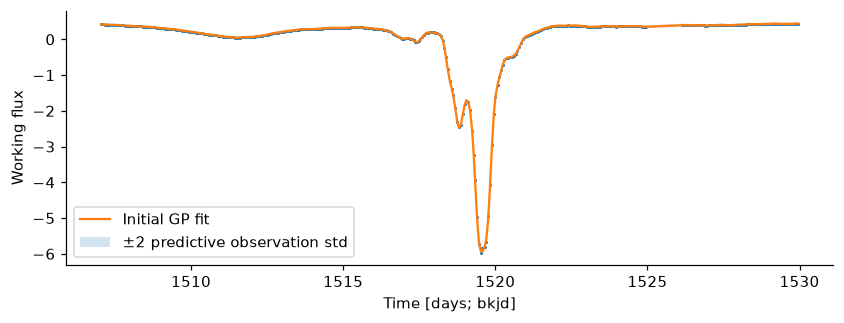

In [3]:
# Bin the observations and standardize flux and propagated measurement errors.
lc = raw.bin(0.06).standardize()

# Optimize the baseline and additional noise jointly, retaining the best state.
fit_settings = dict(kernel="rbf", length_scale=4.0, noise=0.3,
                    iterations=1000, learning_rate=0.05, patience=30,
                    save_state="best")
lc.fit_gp(**fit_settings)
diagnostics = lc.fit_diagnostics
print("GP samples:", len(lc.time), "stop:", diagnostics["stopping_reason"])
print("Selected optimizer step:", diagnostics["selected_state_step"])
print("Learned additional noise variance:", diagnostics["noise_after_adjustment"])

# Show predictive observation uncertainty before excluding candidate intervals.
mean, std = lc.predict(include_noise=True)
fig, ax = lc.plot()
ax.plot(lc.time, mean, label="Initial GP fit")
ax.fill_between(lc.time, mean - 2*std, mean + 2*std, alpha=0.2,
                label="±2 predictive observation std")
ax.legend();

## 4. Run and compare both searches

Both searches use the same fitted GP and working data. Greedy search seeds negative posterior residuals at four residual standard deviations and grows intervals while the retained-data marginal likelihood improves. Exhaustive search evaluates 3–30 sample windows, approximately 0.18–1.8 days at this binning, with a conditional p-value threshold of 10⁻¹⁰. Overlapping selected windows can merge into an event longer than an individual window. Windows crossing gaps larger than five median sampling intervals are excluded.

These settings were assessed on this known-event window and are not independently calibrated. Conditional p-values account for covariance within each candidate window, but not repeated testing or fitted-hyperparameter uncertainty. Neither search uses the known event time as an input or limits the result to one event.

Greedy events: [{'start': 190, 'stop': 233, 'time_start': 1518.4396278853073, 'time_last': 1520.97333655249}]
Exhaustive events: [{'start': 177, 'stop': 240, 'time_start': 1517.6631154717284, 'time_last': 1521.3820069338974}]
Fraction of observations flagged by exhaustive search: 0.1726027397260274


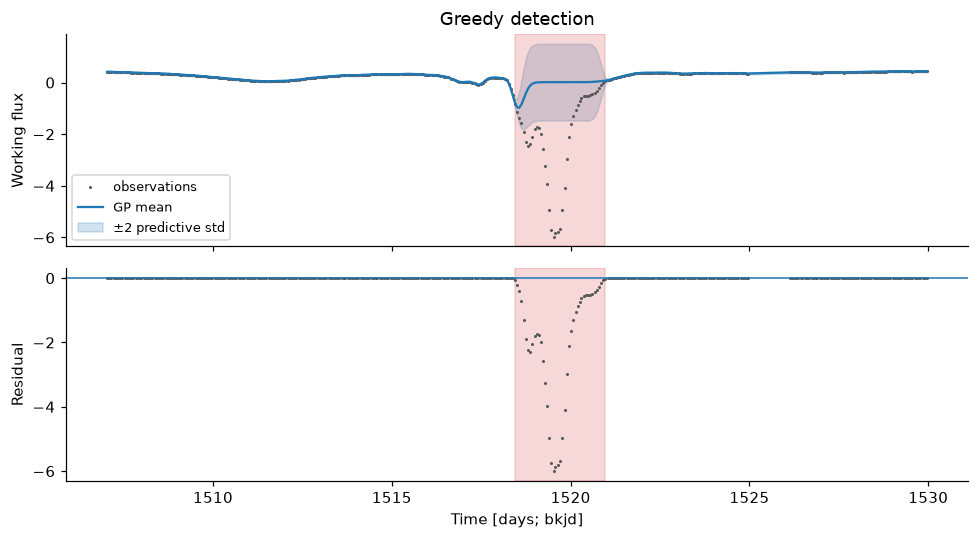

In [4]:
# Grow negative posterior-residual seeds using retained-data marginal likelihood.
greedy_settings = dict(sigma=4, seed_statistic="residual", growth="metric",
                       growth_metric="mll", direction="negative", gap_factor=5,
                       backend="torch")
greedy = lc.greedy_search(**greedy_settings)

# Score held-out windows and exclude those crossing substantial observing gaps.
exhaustive_settings = dict(min_points=3, max_points=30, step=3, size_step=3,
                           threshold=1e-10, direction="negative", gap_factor=5,
                           backend="torch")
exhaustive = lc.exhaustive_search(**exhaustive_settings)

# Inspect greedy recovery; exhaustive conditional predictions are shown below.
greedy.plot();
print("Greedy events:", greedy.events)
print("Exhaustive events:", exhaustive.events)
print("Fraction of observations flagged by exhaustive search:", exhaustive.mask.mean())

The upper panel shows the GP prediction conditioned on observations outside all detected intervals. In the lower panel, each colored curve excludes only its own candidate window. Matching dots identify the excluded observations, and bands show ±2 predictive observation standard deviations. By default, each merged event is represented by its strongest selected candidate, with ties resolved by sample bounds. Use `selection="all"` to show all selected windows, including overlaps. A merged event may span several scored windows. Joint scores use correlations between observations as well as the pointwise uncertainties shown in the bands.

`event_index` selects a merged event by its zero-based index and plots its representative candidate's GP across the full light curve. Other detections remain in the conditioning data. The stored predictions include any candidate-specific refits, so plotting requires no further optimization or live GP. Use `kind="residuals"` to inspect residuals after excluding all detected intervals. Numerical exports include the conditional distributions.

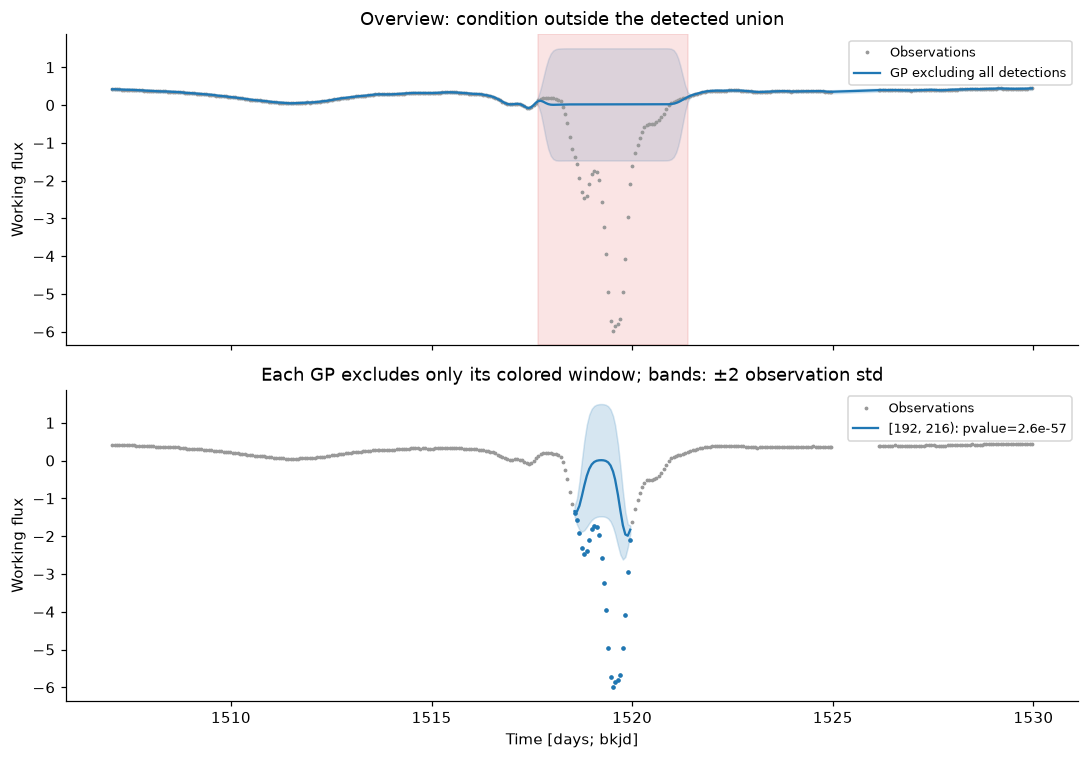

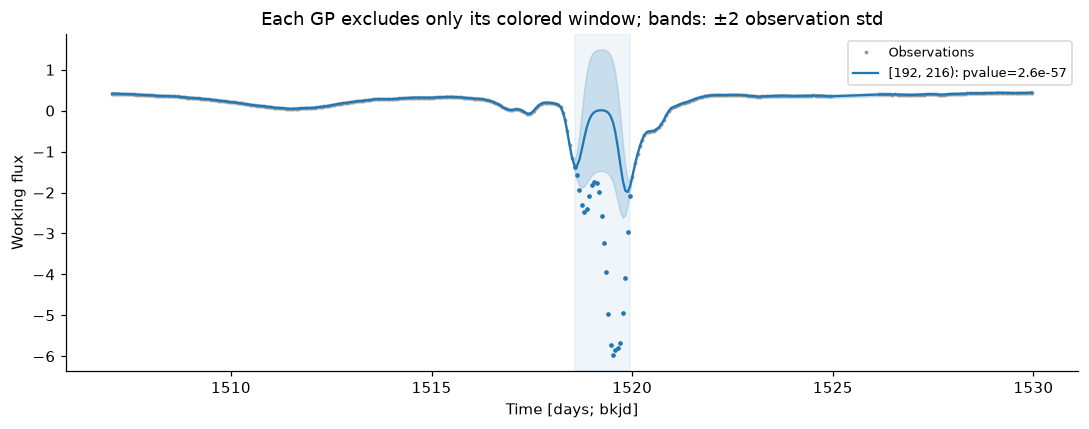

In [5]:
# Inspect the scored conditional fit for one representative window per event.
exhaustive.plot(kind="conditional");

# Plot one candidate's GP over the full light curve, excluding only that window.
if exhaustive.intervals:
    exhaustive.plot(kind="conditional", event_index=0);

# All overlapping selected windows remain accessible with selection="all".
# exhaustive.plot(kind="conditional", selection="all");

Shaded regions combine selected candidate intervals. Their boundaries are detection boundaries, not measured physical ingress or egress times. The overview GP excludes all detected samples; each exhaustive conditional prediction excludes only its own candidate window. Additional detections may arise from residual variability, preprocessing, or instrumental effects. Without a complete truth catalogue, precision and recall are not assigned to these stellar detections.

## 5. Save the run and reproduce figure candidates

The figure gallery uses the exported arrays and configuration to produce PDF and PNG figures showing fits, residuals, event close-ups, and comparisons between methods.

In [6]:
# Choose a configurable directory for numerical results.
output = Path(os.environ.get("NAHIKU_OUTPUT", "outputs"))

# Export search predictions and observation provenance.
greedy.export(output / "tabbys_star_greedy")
exhaustive.export(output / "tabbys_star_exhaustive")
lc.export(output / "tabbys_star_lightcurve")
print("Saved results to", output)

Saved results to /mnt/lustre/koa/koastore/sadow_group/personal/linneamw/research/dipper_detection/codex/results


## 6. Optional full-data recipe

Keep the switch below disabled to run the focused example. Enable it to query the full archive selection. Product availability can change, downloads can be large, and dense GP fitting has cubic cost in sample count. Analyze each observation and each gap-separated segment independently; do not stitch all sectors/quarters into a single covariance matrix. Save a new manifest for each full-data run. The loop uses the same settings as the focused example; validate them before applying them to other epochs.

In [7]:
# Enable archive-wide processing only when a full-data analysis is intended.
RUN_FULL_DATA = False
if RUN_FULL_DATA:
    # Query all epochs matching the remaining mission and pipeline settings.
    selection = {k: v for k, v in manifest["selection"].items() if k not in ("quarter", "sector")}
    # Retrieve all products matching the selected epochs.
    products = lk.search_lightcurve(manifest["target"], **selection)
    full_manifest = {"target": manifest["target"], "products": []}
    for index in range(len(products)):
        # Download one product and convert its valid observations.
        observation = products[index].download(download_dir=str(cache), quality_bitmask="default")
        series = Nahiku.from_lightkurve(observation)
        # Split each observation at substantial time gaps before fitting.
        breaks = np.flatnonzero(np.diff(series.time) > 5*np.median(np.diff(series.time))) + 1
        for segment_id, indices in enumerate(np.split(np.arange(len(series.time)), breaks)):
            if len(indices) < 30:
                continue
            # Limit each dense fit to a bounded time window, with overlap for edge checks.
            window = 23.0
            for start in np.arange(series.time[indices[0]], series.time[indices[-1]], window*0.8):
                keep = indices[(series.time[indices] >= start) & (series.time[indices] < start+window)]
                if len(keep) < 30:
                    continue
                # Construct an independent series for this bounded time window.
                segment = Nahiku(series.time[keep], series.flux[keep], series.flux_err[keep], series.metadata)
                # No prewhitening for this target.
                segment = segment.bin(0.06)
                if len(segment.time) <= 30:
                    continue
                # Fit the baseline using the settings from the focused analysis.
                segment.standardize().fit_gp(**fit_settings)
                # Run both searches and save each window under a distinct name.
                key = f"full_{index}_{segment_id}_{start:.4f}"
                segment.greedy_search(**greedy_settings).export(output / (key+"_greedy"))
                segment.exhaustive_search(**exhaustive_settings).export(output / (key+"_exhaustive"))
        # Record each downloaded product and its checksum.
        full_manifest["products"].append({"uri": str(products.table["dataURI"][index]),
            "sha256": hashlib.sha256(Path(observation.filename).read_bytes()).hexdigest()})
    # Save the archive manifest alongside the per-window results.
    (output / "full_archive_manifest.json").write_text(json.dumps(full_manifest, indent=2))

## Interpret the result

Both searches identify one merged interval around the deep D1500 complex. Exhaustive search flags approximately 17.3% of the focused observations, spanning BKJD 1517.66–1521.38; greedy search identifies BKJD 1518.44–1520.97. The differing boundaries reflect their scoring and interval-growth rules and should not be interpreted as physical ingress or egress measurements. Shallower structure outside these intervals remains unflagged at these settings. Without a complete event catalogue, this result does not establish completeness or a false-positive rate.

Overlapping analysis windows can contain the same physical event. Match detections by observation time before counting events. Review boundary detections and quality flags. Cite NASA Kepler/TESS, MAST, Lightkurve, and the source paper linked above; see the citation guide for software references.

Consult the API reference for parameter and return-value details.